In [1]:
using Flux
using CUDA, cuDNN
using StatsPlots
using Plots;
default(fontfamily="Computer Modern", framestyle=:box) # LaTex-style
using Random
using LaTeXStrings
using Logging;
using ProgressMeter
using StatsBase
using LinearAlgebra
using ParameterSchedulers
using LoggingExtras

In [2]:
begin
    # Define the device selector based on availability
    const device = CUDA.functional() ? gpu : cpu

    if CUDA.functional()
        @info "🚀 Functional GPU detected! Setting device to CUDA."
    else
        @warn "💻 No GPU found. Falling back to host CPU."
    end

    CUDA.allowscalar(false)  # recommended
end

┌ Info: 🚀 Functional GPU detected! Setting device to CUDA.
└ @ Main /home/lf28/Julia/DeepGenModels/jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_W1sdnNjb2RlLXJlbW90ZQ==.jl:6


In [3]:
include("./utils.jl")
include("./io_utils.jl")
batch_size = 128
mnist_binary_loader, mnist_binary_test, mnist_binary_valid = load_binary_mnist_data(batch_size; tensor_shape=(28, 28, 1, :));

In [4]:
function create_mask(conv, type::Symbol=:B)
    conv = get_base_conv(conv)
    mask = similar(conv.weight)
    mask .= 0 ## initialise all to zero
    kh, kw = size(mask)[1:2]
    @assert isodd(kw) && isodd(kh)
    central_idx1 = kh ÷ 2 + 1
    central_idx2 = kw ÷ 2 + 1
    mask[1:(central_idx1-1), :, :, :] .= 1
    mask[central_idx1, 1:central_idx2, :, :] .= 1
    if type == :A
        mask[central_idx1, central_idx2, :, :] .= 0
    end
    return mask
end

create_mask (generic function with 2 methods)

In [5]:
function encode_pix_loc(n::Int, length::Int=5)
    @assert 0 <= n <= 2^length-1 "Number must be between 1 and 31"
    # digits(n, base=2, pad=5) returns least significant bit first.
    return digits(n, base=2, pad=5)
end

function create_loc_embedding(d::Int=28)
    emb_len = ceil(Int, log2(d))
    loc_mat = zeros32(d, d, emb_len*2)
    for i in 1:d
        for j in 1:d
            loc_mat[i, :, 1:emb_len] .= encode_pix_loc(i, emb_len)'
            loc_mat[:, j, (emb_len+1):end] .= encode_pix_loc(j, emb_len)'
        end
    end
    return loc_mat
end

create_loc_embedding (generic function with 2 methods)

In [6]:
struct MaskedConv{C, M}
    conv::C
    mask::M
end



Flux.@layer MaskedConv trainable = (conv,)


function MaskedConv(k_size::Tuple{Int,Int}, ch::Pair{Int,Int}, act::Function=identity; weight_norm=false, kwargs...)
    conv = Conv(k_size, ch, act; pad=:same, kwargs...)
    if weight_norm
        conv = WeightNorm(conv, :weight)
    end
    mask = similar(get_base_conv(conv).weight)
    mask .= 1 ## initialise all to 1
    MaskedConv(conv, mask)
end

function set_mask!(m::MaskedConv, mask)
    @assert size(m.mask) == size(mask)
    m.mask .= mask
end


function (m::MaskedConv)(x)
    base_conv = get_base_conv(m.conv)
    masked_weight = base_conv.weight .* m.mask

    (; pad, stride, dilation, groups) = base_conv
    ## flipped = true: PyTorch convolution
    out = Flux.conv(x, masked_weight; flipped=true, pad, stride, dilation, groups)
    if !(typeof(base_conv.bias) == Bool && base_conv.bias == false)
        out = out .+ reshape(base_conv.bias, 1, 1, :, 1)
    end

    out = base_conv.σ.(out)
    return out
end

# 1. Define a helper function to extract the core Conv layer
# 1. Define a helper function to extract the core Conv layer
get_base_conv(layer::Conv) = layer
get_base_conv(layer::WeightNorm) = layer.layer
get_base_conv(layer::MaskedConv) = get_base_conv(layer.conv)

get_base_conv (generic function with 3 methods)

In [7]:
# function create_mask2(conv::Conv, type::Symbol=:B)
#     mask = similar(conv.weight)
#     mask .= 0 ## initialise all to zero
#     kw, kh = size(mask)[1:2]
#     @assert isodd(kw) && isodd(kh)
#     central_idx1 = kw ÷ 2 + 1
#     central_idx2 = kh ÷ 2 + 1
#     mask[:, 1:(central_idx2-1), :, :] .= 1
#     mask[1:central_idx1, central_idx2, :, :] .= 1
#     if type == :A
#         mask[central_idx1, central_idx2, :, :] .= 0
#     end
#     # return mask
#     return reverse(mask, dims=(1, 2))
#     # return mask
# end

In [8]:
Conv((3,5), 1=>1;dilation =4, pad=:same)

Conv((3, 5), 1 => 1, pad=(4, 4, 8, 8), dilation=4)  # 16 parameters

In [9]:
abstract type AbstractCausalConv2D end

struct CausalConv2D{C} <: AbstractCausalConv2D
    conv::C
    mask_type::Symbol
end



Flux.@layer CausalConv2D trainable = (conv,)


function CausalConv2D(k_size::Tuple{Int,Int}, ch::Pair{Int,Int}, act::Function=identity; weight_norm=false, mask_type::Symbol=:B, kwargs...)
    conv = Conv(k_size, ch, act; pad=0, kwargs...)
    if weight_norm
        conv = WeightNorm(conv, :weight)
    end
    CausalConv2D(conv, mask_type)
end



function (m::CausalConv2D)(xs)
    base_conv = get_base_conv(m.conv)

    kv, kh = size(base_conv.weight)[1:2]
    dv, dh = base_conv.dilation
    top_pad = (kv - 1)*dv
    left_pad = (kh - 1)*dh

    x_padded = Flux.pad_zeros(xs, (top_pad, 0, left_pad, 0); dims=(1, 2))

    out = m.conv(x_padded)
    
    if m.mask_type == :A
        out = Flux.pad_zeros(out, (1, 0); dims=2)[:, 1:(end-1), :, :]
    end
    return out
end


get_base_conv(layer::CausalConv2D) = get_base_conv(layer.conv)

get_base_conv (generic function with 4 methods)

In [10]:
struct CausalConv2DMasked{C} <: AbstractCausalConv2D
    conv::C
    mask_type::Symbol
end

Flux.@layer CausalConv2DMasked trainable = (conv,)


function CausalConv2DMasked(k_size::Tuple{Int,Int}, ch::Pair{Int,Int}, act::Function=identity; weight_norm=false, mask_type::Symbol=:B, kwargs...)
    conv = MaskedConv(k_size, ch, act; weight_norm=weight_norm, kwargs...)
    mask = create_mask(conv, mask_type) ## anti-raster-scan order
    set_mask!(conv, mask)
    CausalConv2DMasked(conv, mask_type)
end


function (m::CausalConv2DMasked)(x)
    return m.conv(x)
end

get_base_conv(layer::CausalConv2D) = get_base_conv(layer.conv)

get_base_conv (generic function with 4 methods)

In [11]:
# MaskedConv((3,3), 1=>2; bias =false).conv.bias

# CausalConv2DMasked((3,3), 1=>2, relu; bias=true, mask_type=:A, init=Flux.kaiming_normal).conv.mask

In [12]:
struct LocationEmbInputWrapper
    add_loc::Bool
    embedding::AbstractArray
end

Flux.@layer LocationEmbInputWrapper # Registers the layer with Flux's backend

function LocationEmbInputWrapper(add_loc::Bool, d::Int)
    embedding = create_loc_embedding(d)
    LocationEmbInputWrapper(add_loc, embedding)
end

# Expects a tuple or pair containing (x, mask)
function (m::LocationEmbInputWrapper)(xs)
    if m.add_loc
        batch_size = size(xs)[end]
        # emb = reshape(m.embedding, size(m.embedding...), 1)
        emb = repeat(m.embedding, 1, 1, 1, batch_size)
        return cat(xs, emb, dims=3)
    else
        return xs
    end
end

In [13]:
struct PixelCNN2D{T<:Chain}
    d::Tuple{Int,Int} ## number of input; or input dimension
    in_ch::Int
    net::T ## trainable network
    add_loc::Bool
end


Flux.@layer PixelCNN2D trainable = (net,)

function PixelCNN2D(d::Tuple{Int,Int}=(28, 28), ch_size::Int=64, k_size::Tuple{Int,Int}=(7, 7), num_layers::Int=4;
    causal_style::Symbol=:masked, # :masked or :shift
    input_ch::Int=1,
    output_ch::Int=1,
    add_loc=false,
    act=relu, kwargs...
)
    in_ch_with_loc = input_ch + add_loc * (2 * ceil(Int, log2(max(d...))))
    loc_wrapper = LocationEmbInputWrapper(add_loc, max(d...))
    net = Any[loc_wrapper]

    input_layer = if causal_style == :shift
        CausalConv2D(k_size, in_ch_with_loc=>ch_size, act; mask_type=:A, kwargs...)
    else
        CausalConv2DMasked(k_size, in_ch_with_loc=>ch_size, act; mask_type=:A, kwargs...)
    end
    push!(net, input_layer)
    for _ in 1:(num_layers-1)
        layer = if causal_style == :shift
            CausalConv2D(k_size, ch_size=>ch_size, act; mask_type=:B, kwargs...)
        else
            CausalConv2DMasked(k_size, ch_size=>ch_size, act; mask_type=:B, kwargs...)
        end
        push!(net, layer)
    end
    output_layer = if causal_style == :shift
        CausalConv2D(k_size, ch_size=>output_ch, identity; mask_type=:B, kwargs...)
    else
        CausalConv2DMasked(k_size, ch_size=>output_ch, identity; mask_type=:B, kwargs...)
    end
    push!(net, output_layer)
    net = Chain(net...)
    return PixelCNN2D(d, input_ch, net, add_loc)
end

function (m::PixelCNN2D)(xs)
    m.net(xs)
end

function logpdf(model, xs::AbstractArray; reduction=mean)
    xs_preds = model(xs)
    loss = Flux.logitbinarycrossentropy(xs_preds, xs; agg=identity)
    -sum(loss, dims=1:2) |> reduction
end


function logpdf(model, data_loader::Union{Flux.DataLoader,DeviceIterator}; reduction=mean)
    logLiks = []
    for (xs,) in data_loader
        xs = xs
        logL = logpdf(model, xs; reduction=identity)[:]
        append!(logLiks, logL)
    end
    return logLiks |> reduction
end

logpdf (generic function with 2 methods)

In [14]:
function sample(model, n=1; raster_scan=true, samples_only=true)
    xs = Array{Float32}(undef, model.d..., model.in_ch, n)
    xs .= 0
    xs = xs |> device
    probs = similar(xs)
    for i in 1:model.d[1]
        for j in 1:model.d[2]
            if raster_scan
                ps = σ.(model(xs))[i, j, :, :]
                xs[i, j, :, :] = (rand_like(ps) .< ps)
                probs[i, j, :, :] = ps
            else
                ps = σ.(model(xs))[j, i, :, :]
                xs[j, i, :, :] = (rand_like(ps) .< ps)
                probs[j, i, :, :] = ps
            end

        end
    end
    if samples_only
        return xs
    else
        return xs, probs
    end
end

sample (generic function with 2 methods)

In [15]:
begin
    Random.seed!(123)
    ch_size = 32
    kernel_size = (5, 5)
    num_layers = 3
    pixcnn = PixelCNN2D((28, 28), ch_size, kernel_size, num_layers; act=relu, bias=true, init=Flux.kaiming_uniform) |> device
    losses_pixcnn, valid_loss = fit!(pixcnn, mnist_binary_loader, Adam(), 15; every_epoch=2, valid_data=mnist_binary_valid)
end

┌ Info: Epoch 1; Loss = 140.5134
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:32
Progress:  13%|█████▌                                   |  ETA: 0:08:10┌ Info: Epoch 3; Loss = 96.0728
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:32
Progress:  27%|██████████▉                              |  ETA: 0:03:37┌ Info: Epoch 5; Loss = 94.5862
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:32
Progress:  40%|████████████████▍                        |  ETA: 0:02:03┌ Info: Epoch 7; Loss = 93.7718
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:32
Progress:  53%|█████████████████████▉                   |  ETA: 0:01:14┌ Info: Epoch 9; Loss = 93.2238
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:32
Progress:  67%|███████████████████████████▍             |  ETA: 0:00:44┌ Info: Epoch 11; Loss = 92.8365
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:32
Progress:  80%|████████████████████████████████▊        |  ETA: 0:00:23┌ Info: Epoch 13; Loss = 92.5807
└ @ Main /home/lf28/Julia/DeepGenMo

(Any[528.5022f0, 503.32547f0, 485.27594f0, 481.2351f0, 484.14194f0, 479.96558f0, 474.768f0, 464.84448f0, 461.66174f0, 452.6808f0  …  88.82197f0, 95.151855f0, 92.54706f0, 94.26105f0, 93.11616f0, 93.737f0, 93.68425f0, 93.40092f0, 92.14765f0, 94.40639f0], Any[98.92425f0, 96.69402f0, 95.45538f0, 95.460365f0, 94.277534f0, 93.93691f0, 93.67185f0, 93.62384f0, 93.21661f0, 92.9463f0, 92.85295f0, 93.39638f0, 92.51649f0, 92.48777f0, 92.315f0])

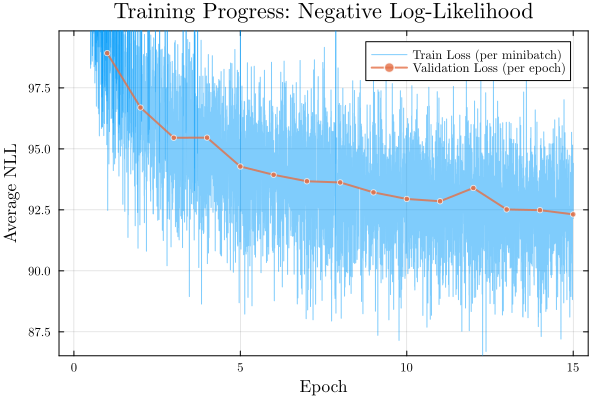

In [16]:
plot_loss_history(losses_pixcnn, valid_loss, mnist_binary_loader; xscale=:linear)

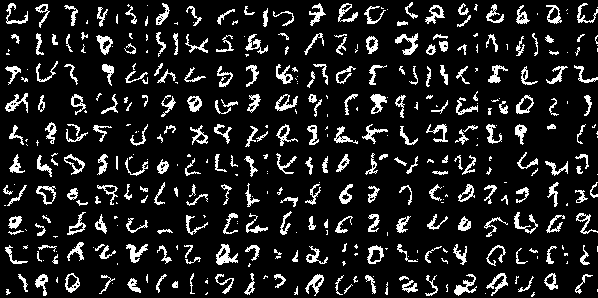

In [17]:
tensor2imgs(sample(pixcnn, 200); nrows=10)

In [18]:
logpdf(pixcnn, mnist_binary_test |> device)

-91.85092f0

In [19]:
Random.seed!(1234)
pixcnn_loc = PixelCNN2D((28, 28), ch_size, kernel_size, num_layers; add_loc=true, act=gelu, bias=true, init=Flux.kaiming_uniform) |> device
losses_pixcnn_loc, valid_loss_loc = fit!(pixcnn_loc, mnist_binary_loader, Adam(), 50; every_epoch=5, valid_data=mnist_binary_valid)

┌ Info: Epoch 1; Loss = 136.5342
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:32
Progress:  10%|████▏                                    |  ETA: 0:03:38┌ Info: Epoch 6; Loss = 90.4697
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:32
Progress:  20%|████████▎                                |  ETA: 0:02:15┌ Info: Epoch 11; Loss = 88.6477
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:32
Progress:  30%|████████████▎                            |  ETA: 0:01:42┌ Info: Epoch 16; Loss = 87.9244
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:32
Progress:  40%|████████████████▍                        |  ETA: 0:01:20┌ Info: Epoch 21; Loss = 87.4463
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:32
Progress:  50%|████████████████████▌                    |  ETA: 0:01:03┌ Info: Epoch 26; Loss = 87.1324
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:32
Progress:  60%|████████████████████████▋                |  ETA: 0:00:49┌ Info: Epoch 31; Loss = 86.8777
└ @ Main /home/lf28/Julia/DeepGe

(Any[524.96826f0, 470.1233f0, 424.99564f0, 408.5575f0, 421.35687f0, 397.21204f0, 385.00012f0, 373.76047f0, 356.67444f0, 363.01245f0  …  84.07532f0, 85.789246f0, 83.63928f0, 83.7899f0, 85.59383f0, 86.7092f0, 88.136f0, 82.98168f0, 88.95091f0, 84.55981f0], Any[98.23731f0, 94.56485f0, 92.78654f0, 91.80114f0, 90.934784f0, 90.92741f0, 89.74671f0, 89.328125f0, 89.14864f0, 88.92144f0  …  86.86921f0, 86.89327f0, 86.82602f0, 86.75377f0, 86.7758f0, 86.736275f0, 86.69594f0, 86.6159f0, 86.797905f0, 86.65447f0])

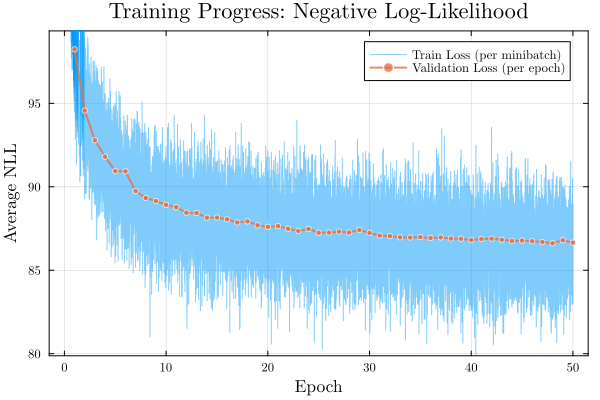

In [20]:
plot_loss_history(losses_pixcnn_loc, valid_loss_loc, mnist_binary_loader; xscale=:linear)

In [21]:
logpdf(pixcnn_loc, mnist_binary_test |> device)

-86.16739f0

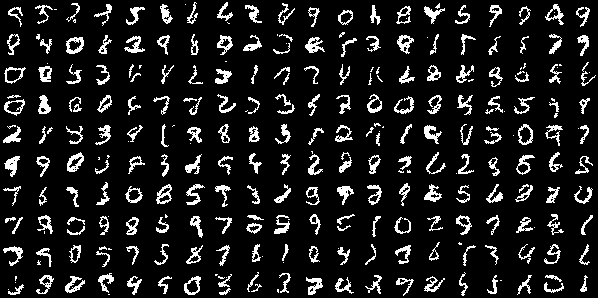

In [22]:
set_rand_seed(1234)
xs_samples, probs_samples = sample(pixcnn_loc, 200; samples_only=false)
tensor2imgs(xs_samples; nrows=10)

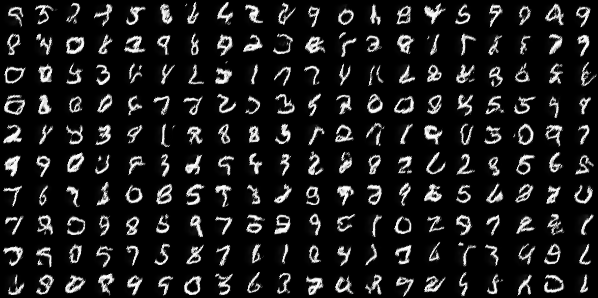

In [23]:
tensor2imgs(probs_samples; nrows=10)

In [24]:
function plot_receptive_field(model, xs)
    H = max(size(xs)[1:2]...)
    central_pixel = H ÷ 2 + 1
    gx = Flux.gradient(xs) do xs
        out = model(xs)
        out[central_pixel, central_pixel, 1, 1]
    end

    grad_img = Float32.((abs.(gx[1]) .> 1f-8)[:, :, 1, 1])
    # grad_img[central_pixel, central_pixel] = 0.5

    if grad_img[central_pixel, central_pixel] > 0
        grad_img[central_pixel, central_pixel] = 1
    else
        grad_img[central_pixel, central_pixel] = 0.5
    end
    layer_len = 1

    if hasproperty(model, :net)
        layer_len = length(model.net)-1
    end
    heatmap(grad_img, yflip=true, ratio=1, xlims=[1, H], ylims=[1, H], legend=false, c=:viridis, title="Receptive field from the centre with $(layer_len) layers")
end

plot_receptive_field (generic function with 1 method)

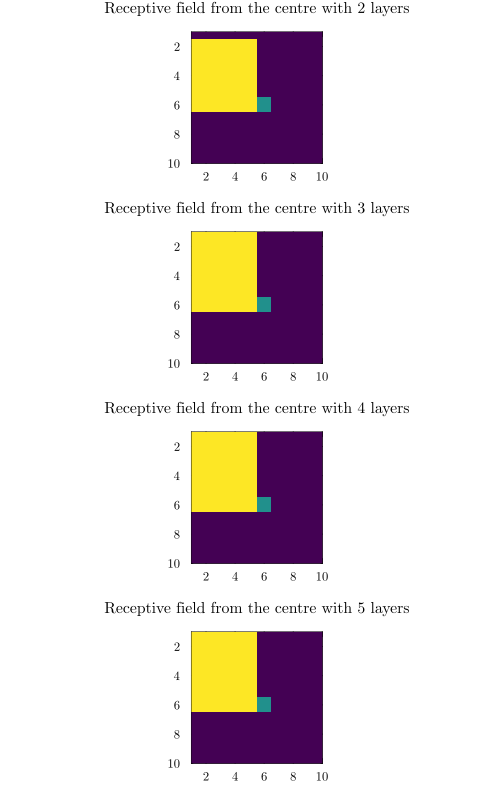

In [25]:
plts = []
for layer in 1:4
    toy_pixelcnn = PixelCNN2D((28, 28), 1, (3, 3), layer; act=identity, causal_style=:shift)

    plt = plot_receptive_field(toy_pixelcnn, randn32(10, 10, 1, 1))
    push!(plts, plt)
end

plot(plts..., layout=(4, 1), size=(500, 800), titlefontsize=10)

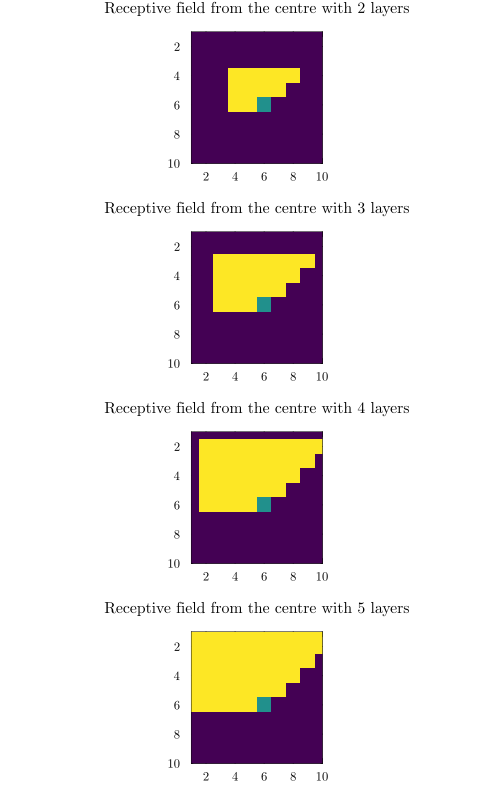

In [26]:
plts = []
for layer in 1:4
    toy_pixelcnn = PixelCNN2D((28, 28), 1, (3, 3), layer; act=identity, causal_style=:mask)

    plt = plot_receptive_field(toy_pixelcnn, randn32(10, 10, 1, 1))
    push!(plts, plt)
end

plot(plts..., layout=(4, 1), size=(500, 800), titlefontsize=10)

In [27]:
abstract type AbstractCausalConvVert end

abstract type AbstractCausalConvHori end
"""
This implements vertical causal convolution, which is equivalent to masking the weight matrix up to the center row
- include_mid_row:: a bool variable that check whether the center row is masked or not
"""
struct CausalConvVertMasked{C} <: AbstractCausalConvVert
    conv::C
    include_mid_row::Bool ## include the middle row or not
end

Flux.@layer CausalConvVertMasked trainable = (conv,)


function CausalConvVertMasked(k_size::Tuple{Int,Int}, ch::Pair{Int,Int}, act::Function=identity;
    weight_norm::Bool=false, include_mid_row::Bool=true, kwargs...)
    # conv = Conv(k_size, ch, act; pad=0, kwargs...) ## apply valid convolution; we pad input x manually
    conv = MaskedConv(k_size, ch, act; weight_norm=weight_norm, kwargs...)
    kh, kw = k_size
    @assert isodd(kw) && isodd(kh)
    central_idx1 = kh ÷ 2 + 1
    conv.mask .= 0 ## reset the mask to 0s
    if include_mid_row
        conv.mask[1:central_idx1, :, :, :] .= 1
    else
        conv.mask[1:(central_idx1-1), :, :, :] .= 1
    end
    CausalConvVertMasked(conv, include_mid_row)
end


function (m::CausalConvVertMasked)(xs)
    out = m.conv(xs)
    return out
end


get_base_conv(layer::CausalConvVertMasked) = get_base_conv(layer.conv)


get_base_conv (generic function with 5 methods)

In [28]:
"""
This implements horizontal 1d causal convolution, where left and up to the pixel are conditioned where the rest are masked
- type:: A or B, which includes the current pixel or not
"""
struct CausalConvHoriMasked{C} <: AbstractCausalConvHori
    conv::C
    mask_type::Symbol
end


Flux.@layer CausalConvHoriMasked trainable = (conv,)


function CausalConvHoriMasked(kernel_size::Int, ch::Pair{<:Integer,<:Integer}, act=identity;
    mask_type::Symbol=:A, weight_norm::Bool=false, kwargs...)
    # conv = MaskedConv((1, kernel_size), ch, act; mask_type = type, weight_norm=weight_norm, kwargs...)
    conv = CausalConv2DMasked((1, kernel_size), ch, act; mask_type = mask_type, weight_norm=weight_norm, kwargs...)
    CausalConvHoriMasked(conv, mask_type)
end

function (m::CausalConvHoriMasked)(x::AbstractArray)
    return m.conv(x)
end


get_base_conv(layer::CausalConvHoriMasked) = get_base_conv(layer.conv)

get_base_conv (generic function with 6 methods)

In [29]:
"""
This implements vertical causal convolution, which is equivalent to masking the weight matrix up to the center row
- include_mid_row:: a bool variable that check whether the center row is masked or not
"""
struct CausalConvVert{C}  <: AbstractCausalConvVert
    conv::C
    include_mid_row::Bool ## include the middle row or not
end

Flux.@layer CausalConvVert trainable = (conv,)


function CausalConvVert(k_size::Tuple{Int,Int}, ch::Pair{Int,Int}, act::Function=identity;
    weight_norm::Bool=false, include_mid_row::Bool=true, kwargs...)
    conv = Conv(k_size, ch, act; pad=0, kwargs...) ## apply valid convolution; we pad input x manually
    @assert isodd(k_size[1]) && isodd(k_size[2])
    # Conditionally wrap it in WeightNorm
    if weight_norm
        conv = WeightNorm(conv, :weight)
        conv.g .= 1.0
    end
    CausalConvVert(conv, include_mid_row)
end

# 1. Define a helper function to extract the core Conv layer
# get_base_conv(layer::Conv) = layer
# get_base_conv(layer::WeightNorm) = layer.layer

function (m::CausalConvVert)(xs)
    base_conv = get_base_conv(m.conv)
    kv, kh = size(base_conv.weight)[1:2]
    dv, dh = base_conv.dilation
    left_right_pad = ((kh-1) * dh) ÷ 2
    top_pad = (kv - 1)*dv
    x_padded = Flux.pad_zeros(xs, (top_pad, 0, left_right_pad, left_right_pad); dims=(1, 2)) ## make sure the h size remains the same
    out = m.conv(x_padded)
    if !m.include_mid_row
        out = Flux.pad_zeros(out, (1, 0); dims=1)[1:(end-1), :, :, :]
    end
    return out
end

get_base_conv(layer::CausalConvVert) = get_base_conv(layer.conv)

get_base_conv (generic function with 7 methods)

In [ ]:
"""
This implements horizontal 1d causal convolution, where left and up to the pixel are conditioned where the rest are masked
- type:: A or B, which includes the current pixel or not
"""
struct CausalConvHori{C} <: AbstractCausalConvHori
    conv::C
    mask_type::Symbol
end


Flux.@layer CausalConvHori trainable = (conv,)


function CausalConvHori(kernel_size::Int, ch::Pair{<:Integer,<:Integer}, act=identity; 
    mask_type::Symbol=:A, weight_norm::Bool=false, kwargs...)
    conv = Conv((1, kernel_size), ch, act; pad=0, kwargs...)

    # Conditionally wrap it in WeightNorm
    if weight_norm
        conv = WeightNorm(conv, :weight)
        conv.g .= 1.0 
    end
    return CausalConvHori(conv, mask_type)
end

function (m::CausalConvHori)(x::AbstractArray)
    # Layout assumed: (W, H, C, Batch)
    base_conv = get_base_conv(m.conv)
    k = size(base_conv.weight, 2)
    d = base_conv.dilation[2]
    # Calculate required causal left-padding
    left_pad = (k - 1) * d + (m.mask_type == :A)
    # Left-pad with zeros asymmetrically
    x_padded = Flux.pad_zeros(x, (left_pad, 0); dims=2)
    out = m.conv(x_padded)
    return out[:, 1:size(x,2), :, :]
end

get_base_conv(layer::CausalConvHori) = get_base_conv(layer.conv)

get_base_conv (generic function with 8 methods)

In [31]:
# Define a stateless, parameterless layer struct
struct GatedActivation 
    channel_dim::Int ## which dimension to split the input into two
end

Flux.@layer GatedActivation trainable=()

GatedActivation(; d::Int=3) = GatedActivation(d)

function (g::GatedActivation)(x)
    total_channels = size(x, g.channel_dim)
    out_ch = total_channels ÷ 2
    f_path = x[:, :, 1:out_ch, :]
    g_path = x[:, :, (out_ch + 1):end, :]
    return tanh.(f_path) .* σ.(g_path)
end

In [32]:
struct CausalPixCNNConv2D{V<:AbstractCausalConvVert,H<:AbstractCausalConvHori,C<:Conv}
    vert_conv::V
    hori_conv::H
    v2hori::C
    res_conv::C
    gated::Bool
    mask_type::Symbol
    act::Union{Function,GatedActivation}
end

Flux.@layer CausalPixCNNConv2D trainable=(vert_conv, hori_conv, v2hori, res_conv)

function CausalPixCNNConv2D(k_size::Int, ch::Pair{Int,Int}, act::Function=relu;
    vert_causal_style::Symbol=:shift, # :masked or :shift
    hori_causal_style::Symbol=:shift, # :masked or :shift
    weight_norm=true, 
    gated::Bool=true,
    mask_type::Symbol=:B,
    kwargs...
)
    in_ch, out_ch = ch
    out_ch_inner = gated ? 2 * out_ch : out_ch
    vert_conv = if vert_causal_style == :shift
        CausalConvVert((k_size, k_size), in_ch => out_ch_inner, identity;
            weight_norm=weight_norm, include_mid_row=true, kwargs...)
    else
        CausalConvVertMasked((k_size, k_size), in_ch => out_ch_inner, identity;
            weight_norm=weight_norm, include_mid_row=true, kwargs...)
    end

    hori_conv = if hori_causal_style==:shift
        CausalConvHori(k_size, in_ch => out_ch_inner, identity;
            weight_norm=weight_norm, mask_type=mask_type, kwargs...)
    else
        CausalConvHoriMasked(k_size, in_ch => out_ch_inner, identity;
            weight_norm=weight_norm, mask_type=mask_type, kwargs...)
    end

    v2hori = Conv((1, 1), out_ch_inner => out_ch_inner, identity; kwargs...)
    res_conv = Conv((1, 1), out_ch => out_ch, identity; kwargs...)
    if gated ## if gated activation, we replace relu with gated activation
        ch_dim = 3
        act = GatedActivation(ch_dim)
    end
    return CausalPixCNNConv2D(vert_conv, hori_conv, v2hori, res_conv, gated, mask_type, act)
end

function down_shift(xs::AbstractArray)
    xs = xs[1:(end-1), :, :, :]
    return Flux.pad_zeros(xs, (1, 0), dims=1)
end

function (m::CausalPixCNNConv2D)((xh, xv))
    out_v = m.vert_conv(xv)
    out_h = m.hori_conv(xh)
    out_h = out_h + m.v2hori(down_shift(out_v))
    out_v = m.act(out_v)
    out_h = m.act(out_h)
    out_h = m.res_conv(out_h)
    if m.mask_type == :A ## this is input layer
        out_h = out_h ## if type A, no residual connection allowed, information leaking otherwise
    else
        out_h = out_h + xh
    end
    return out_h, out_v
end

In [33]:
struct PixelCNNTwoStack{T<:Chain,Y<:Chain}
    d::Tuple{Int,Int} ## number of input; or input dimension
    in_ch::Int
    input_layer::T
    net::Y ## trainable network
    output_layer::Conv
end


Flux.@layer PixelCNNTwoStack trainable = (input_layer, net, output_layer)

function PixelCNNTwoStack(d::Tuple{Int,Int}=(28, 28), ch_size::Int=64, k_size::Int=3, num_layers::Int=4;
    input_ch::Int=1, output_ch::Int=1,
    vert_causal_style::Symbol=:shift, # :masked or :shift
    hori_causal_style::Symbol=:shift, # :masked or :shift
    weight_norm=false,
    gated=true,
    add_loc=false,
    act=relu,
    kwargs...
)
    in_ch_with_loc = input_ch + add_loc * (2 * ceil(Int, log2(max(d...))))
    loc_wrapper = LocationEmbInputWrapper(add_loc, max(d...))

    input_layer = Chain(loc=loc_wrapper, inpt_layer=CausalPixCNNConv2D(k_size, in_ch_with_loc=>ch_size, act;
        vert_causal_style=vert_causal_style, hori_causal_style=hori_causal_style,
        weight_norm=weight_norm, gated=gated, mask_type=:A, kwargs...))
    net = Any[]
    for _ in 1:(num_layers-1)
        push!(net, CausalPixCNNConv2D(k_size, ch_size=>ch_size, act;
            vert_causal_style=vert_causal_style, hori_causal_style=hori_causal_style,
            weight_norm=weight_norm, gated=gated, mask_type=:B, kwargs...))
    end
    net = Chain(net...)
    output_layer = Conv((1, 1), ch_size => 1)
    return PixelCNNTwoStack(d, input_ch, input_layer, net, output_layer)
end

function (m::PixelCNNTwoStack)(xs)
    xs = m.input_layer.layers.loc(xs)
    outh, outv = m.input_layer.layers.inpt_layer((xs, xs))
    if !isempty(m.net)
        (outh, outv) = m.net((outh, outv))
    end
    logits = m.output_layer(outh)
end

In [34]:
# CausalConvVert((3,3), 2=>1, identity; weight_norm=true, include_mid_row=false, pad=0, init= Flux.kaiming_uniform)

In [35]:
Random.seed!(1234)
pixcnn2stacks = PixelCNNTwoStack((28, 28), 32, 3, 6; add_loc=true, weight_norm=true, init=Flux.kaiming_uniform) |> device
losses_pixcnn2stacks, valid_loss_pixcnn2stacks = fit!(pixcnn2stacks, mnist_binary_loader, Adam(0.001), 25;
    every_epoch=2, valid_data=mnist_binary_valid)

┌ Info: Epoch 1; Loss = 119.6475
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:32
Progress:   8%|███▎                                     |  ETA: 0:19:56┌ Info: Epoch 3; Loss = 89.7847
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:32
Progress:  16%|██████▌                                  |  ETA: 0:13:53┌ Info: Epoch 5; Loss = 87.5921
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:32
Progress:  24%|█████████▉                               |  ETA: 0:11:14┌ Info: Epoch 7; Loss = 86.6333
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:32
Progress:  32%|█████████████▏                           |  ETA: 0:09:27┌ Info: Epoch 9; Loss = 86.0162
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:32
Progress:  40%|████████████████▍                        |  ETA: 0:08:02┌ Info: Epoch 11; Loss = 85.5607
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:32
Progress:  48%|███████████████████▋                     |  ETA: 0:06:47┌ Info: Epoch 13; Loss = 85.2139
└ @ Main /home/lf28/Julia/DeepGenMo

(Any[810.4661f0, 503.93484f0, 488.68567f0, 422.66806f0, 330.14853f0, 284.88562f0, 321.96732f0, 301.5232f0, 257.39752f0, 238.89531f0  …  84.77831f0, 85.706474f0, 86.37151f0, 84.304474f0, 85.19761f0, 82.98015f0, 81.81396f0, 85.70747f0, 83.54718f0, 83.374664f0], Any[96.33169f0, 90.810356f0, 88.91125f0, 88.363235f0, 87.274796f0, 86.91036f0, 86.59682f0, 86.30723f0, 85.98631f0, 86.03272f0  …  85.1802f0, 85.06464f0, 84.84649f0, 84.863205f0, 84.8309f0, 84.70355f0, 84.61265f0, 84.48676f0, 84.49992f0, 84.341446f0])

In [36]:
Random.seed!(1234)
pixcnn2stacks_masked = PixelCNNTwoStack((28, 28), 32, 3, 6;
    vert_causal_style=:masked, hori_causal_style=:masked,
    add_loc=true, weight_norm=true, init=Flux.kaiming_uniform) |> device
losses_pixcnn2stacks_masked, valid_loss_pixcnn2stacks_masked = fit!(pixcnn2stacks_masked, mnist_binary_loader, Adam(0.001), 25;
    every_epoch=2, valid_data=mnist_binary_valid)

┌ Info: Epoch 1; Loss = 107.6348
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:32
Progress:   8%|███▎                                     |  ETA: 0:09:47┌ Info: Epoch 3; Loss = 89.7076
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:32
Progress:  16%|██████▌                                  |  ETA: 0:07:48┌ Info: Epoch 5; Loss = 88.1059
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:32
Progress:  24%|█████████▉                               |  ETA: 0:06:41┌ Info: Epoch 7; Loss = 87.284
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:32
Progress:  32%|█████████████▏                           |  ETA: 0:05:50┌ Info: Epoch 9; Loss = 86.7532
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:32
Progress:  40%|████████████████▍                        |  ETA: 0:05:04┌ Info: Epoch 11; Loss = 86.37
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:32
Progress:  48%|███████████████████▋                     |  ETA: 0:04:21┌ Info: Epoch 13; Loss = 86.0694
└ @ Main /home/lf28/Julia/DeepGenModel

(Any[470.96008f0, 379.5873f0, 318.9822f0, 280.26752f0, 260.06107f0, 257.06378f0, 244.35178f0, 215.3326f0, 203.83902f0, 204.91322f0  …  85.774124f0, 87.30243f0, 87.49416f0, 85.63697f0, 86.28366f0, 84.17592f0, 83.046555f0, 87.08482f0, 84.357605f0, 84.54588f0], Any[93.72752f0, 90.299164f0, 89.03096f0, 88.59281f0, 87.82096f0, 87.51525f0, 87.2732f0, 86.93194f0, 86.72809f0, 86.74716f0  …  86.15396f0, 85.95093f0, 85.697266f0, 85.75814f0, 85.698364f0, 85.63665f0, 85.548134f0, 85.466095f0, 85.468f0, 85.34227f0])

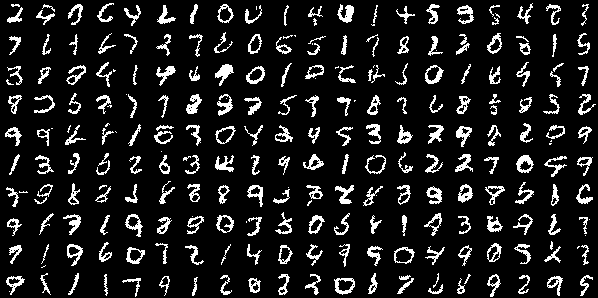

In [37]:
tensor2imgs(sample(pixcnn2stacks, 200); nrows=10)

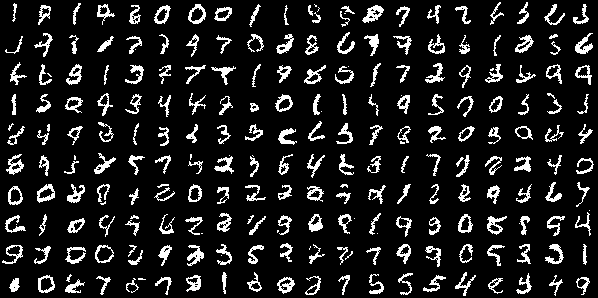

In [38]:
tensor2imgs(sample(pixcnn2stacks_masked, 200); nrows=10)

In [39]:
logpdf(pixcnn2stacks, mnist_binary_test |> device)

-83.92552f0

In [40]:
logpdf(pixcnn2stacks_masked, mnist_binary_test |> device)

-84.89738f0

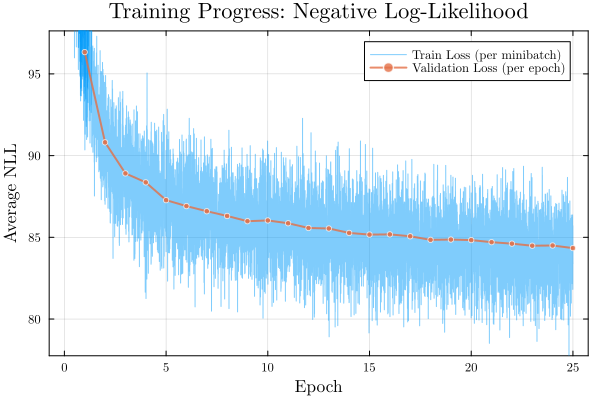

In [41]:
plot_loss_history(losses_pixcnn2stacks,valid_loss_pixcnn2stacks, mnist_binary_loader; xscale=:linear)

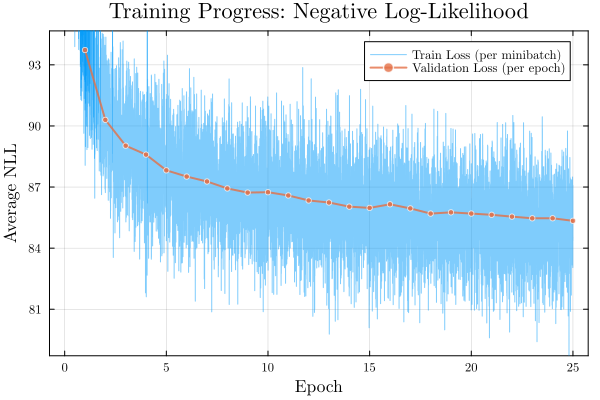

In [42]:
plot_loss_history(losses_pixcnn2stacks_masked, valid_loss_pixcnn2stacks_masked, mnist_binary_loader; xscale=:linear)

In [43]:
Random.seed!(1234)
pixcnn2stacks_relu = PixelCNNTwoStack((28, 28), 32, kernel_size[1], num_layers;
    add_loc=true, weight_norm=true, gated=false, init=Flux.kaiming_uniform) |> device
losses_pixcnn2stacks_relu, _ = fit!(pixcnn2stacks_relu, mnist_binary_loader, Adam(), 30; every_epoch=2, valid_data=nothing)

┌ Info: Epoch 1; Loss = 433.3356
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:32
Progress:   7%|██▊                                      |  ETA: 0:04:39┌ Info: Epoch 3; Loss = 106.8494
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:32
Progress:  13%|█████▌                                   |  ETA: 0:03:53┌ Info: Epoch 5; Loss = 100.7741
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:32
Progress:  20%|████████▎                                |  ETA: 0:03:25┌ Info: Epoch 7; Loss = 97.6829
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:32
Progress:  27%|██████████▉                              |  ETA: 0:03:05┌ Info: Epoch 9; Loss = 95.2986
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:32
Progress:  33%|█████████████▋                           |  ETA: 0:02:46┌ Info: Epoch 11; Loss = 93.3128
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:32
Progress:  40%|████████████████▍                        |  ETA: 0:02:28┌ Info: Epoch 13; Loss = 91.8377
└ @ Main /home/lf28/Julia/DeepGen

(Any[13047.322f0, 17252.111f0, 18466.703f0, 13983.695f0, 8912.08f0, 4593.666f0, 1946.1298f0, 3411.0742f0, 2772.1353f0, 1469.7068f0  …  86.61493f0, 87.41588f0, 85.37504f0, 89.766754f0, 86.98836f0, 85.03783f0, 87.42108f0, 88.26202f0, 88.74017f0, 92.85866f0], Any[])

In [44]:
logpdf(pixcnn2stacks_relu, mnist_binary_test |> device)

-87.19915f0

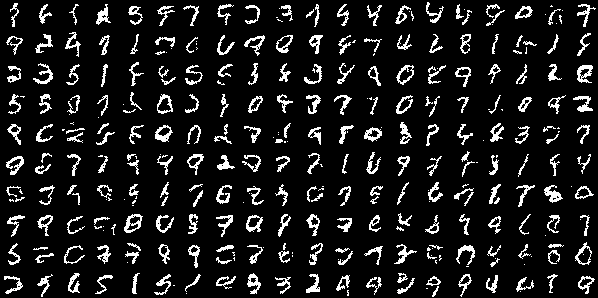

In [45]:
tensor2imgs(sample(pixcnn2stacks_relu, 200); nrows=10)

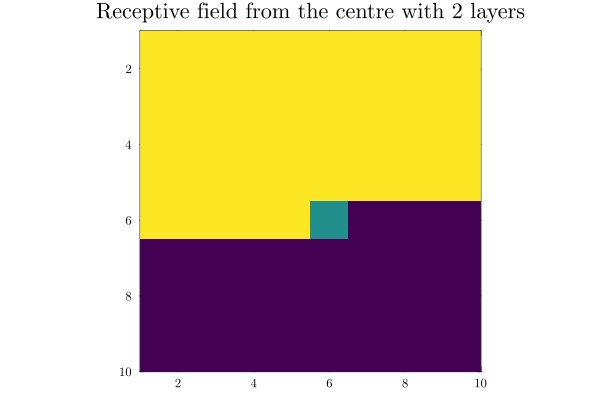

In [46]:
pxnnt = PixelCNNTwoStack((28,28),  1, 3, 4; act=identity, weight_norm=true, gated=true, bias =false, init=Flux.kaiming_uniform)

xs = randn32(10, 10, 1, 1)

plot_receptive_field(pxnnt, xs)

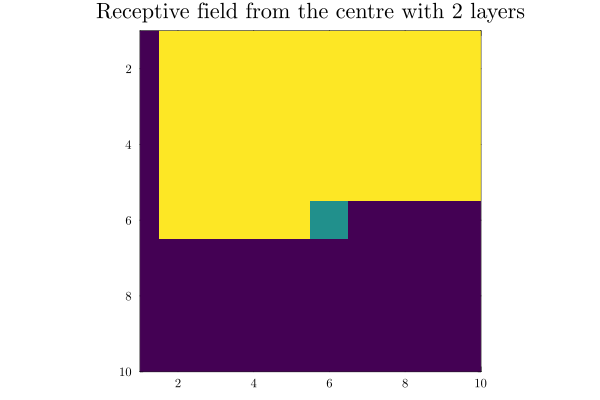

In [47]:
pxnnt = PixelCNNTwoStack((28,28),  1, 3, 4; vert_causal_style=:masked, hori_causal_style=:masked, act=identity, weight_norm=true, gated=true, bias =false, init=Flux.kaiming_uniform)


xs = randn32(10, 10, 1, 1)

plot_receptive_field(pxnnt, xs)

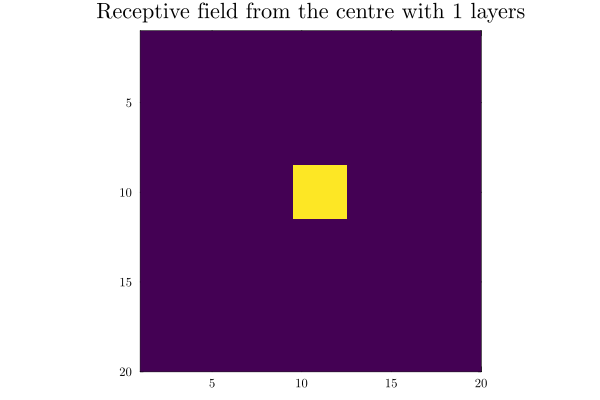

In [48]:
Random.seed!(1234)
hconv = CausalConvHori(5, (1=>1); mask_type=:A)

vconv = CausalConvVert((3,3), (1=>1))

xs = randn32(20, 20, 1, 1)

plot_receptive_field(vconv, xs)

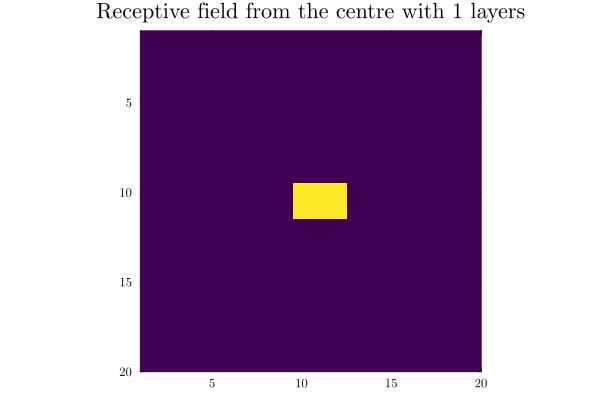

In [49]:
hconvm = CausalConvHoriMasked(5, (1=>1); mask_type=:A, bias =false)

vconvm = CausalConvVertMasked((3,3), (1=>1))


plot_receptive_field(vconvm, xs)